# Running TFLite Models

## Setup

In [1]:
# Set tensorflow version for compatibility
#!pip install tensorflow==2.15

In [1]:
import pathlib
import numpy as np
import matplotlib.pyplot as plt

#import tensorflow as tf
import keras

print('\u2022 Using Keras Version:', keras.__version__)

• Using Keras Version: 3.15.1


## Create a Basic Model of the Form y = mx + c

In [5]:
# Create a simple Keras model.
x = np.array([-1, 0, 1, 2, 3, 4])
y = np.array([-3, -1, 1, 3, 5, 7])

model = keras.models.Sequential([
        keras.layers.Dense(units=1, input_shape=[1])
])

model.compile(optimizer='sgd',
              loss='mean_squared_error')

model.fit(x, y, epochs=200)

d:\DOCUMENTOS\PROJECTS\MachineLearning_COURSE\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 492ms/step - loss: 39.5242
Epoch 2/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - loss: 31.4488
Epoch 3/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - loss: 25.0881
Epoch 4/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - loss: 20.0767
Epoch 5/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - loss: 16.1271
Epoch 6/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - loss: 13.0129
Epoch 7/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - loss: 10.5561
Epoch 8/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - loss: 8.6167
Epoch 9/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - loss: 7.0845
Epoch 10/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - loss: 5.8727
Epoch 11/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - loss: 4.9132
Epoch 12/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - loss: 4.1523
Epoch 13/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - loss: 3.5478
Epoch 14/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - loss: 3.0664
Epoch 15/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - loss: 2.6820
Epoch 16/20

## Generate a SavedModel

In [6]:
import tensorflow as tf

In [7]:
export_dir = 'saved_model/1'
tf.saved_model.save(model, export_dir)

INFO:tensorflow:Assets written to: saved_model/1\assets


INFO:tensorflow:Assets written to: saved_model/1\assets


## Convert the SavedModel to TFLite

In [8]:
# Convert the model.
converter = tf.lite.TFLiteConverter.from_saved_model(export_dir)
tflite_model = converter.convert()

In [9]:
tflite_model_file = pathlib.Path('model.tflite')
tflite_model_file.write_bytes(tflite_model)

1744

## Initialize the TFLite Interpreter To Try It Out

In [10]:
# Load TFLite model and allocate tensors.
interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()

# Get input and output tensors.
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

d:\DOCUMENTOS\PROJECTS\MachineLearning_COURSE\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [11]:
# Test the TensorFlow Lite model on random input data.
input_shape = input_details[0]['shape']
inputs, outputs = [], []
for _ in range(100):
    input_data = np.array(np.random.random_sample(input_shape), dtype=np.float32)
    interpreter.set_tensor(input_details[0]['index'], input_data)
    
    interpreter.invoke()
    tflite_results = interpreter.get_tensor(output_details[0]['index'])
    
    # Test the TensorFlow model on random input data.
    tf_results = model(tf.constant(input_data))
    output_data = np.array(tf_results)
    
    inputs.append(input_data[0][0])
    outputs.append(output_data[0][0])

## Visualize the Model

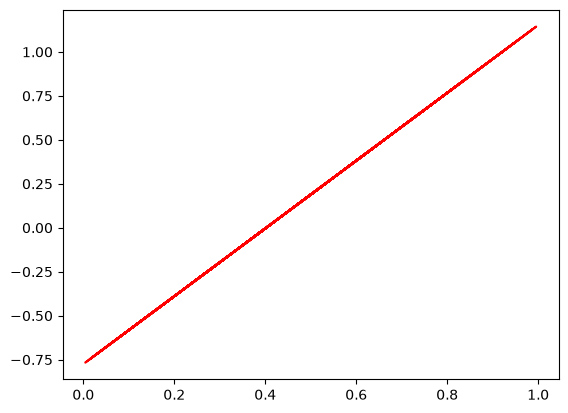

In [12]:
%matplotlib inline

plt.plot(inputs, outputs, 'r')
plt.show()

## Download the TFLite Model File

If you are running this notebook in a Colab, you can run the cell below to download the tflite model to your local disk. 

**Note**: If the file does not download when you run the cell, try running the cell a second time.

In [13]:
try:
    from google.colab import files
    files.download(tflite_model_file)
except:
    pass

In [14]:
header_path = pathlib.Path("model.h")
array_name = "g_model"

with header_path.open("w") as header:
    header.write("#ifndef MODEL_H_\n#define MODEL_H_\n\n")
    header.write(f"const unsigned char {array_name}[] = {{\n")

    for offset in range(0, len(tflite_model), 12):
        chunk = tflite_model[offset:offset + 12]
        header.write("  " + ", ".join(f"0x{byte:02x}" for byte in chunk) + ",\n")

    header.write("};\n")
    header.write(f"const unsigned int {array_name}_len = {len(tflite_model)};\n\n")
    header.write("#endif  // MODEL_H_\n")

print(f"Exported {len(tflite_model)} bytes to {header_path}")

Exported 1744 bytes to model.h
